In [20]:
import torch
from torchvision import datasets, transforms

In [21]:
from torch.utils.data import DataLoader
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
fashion_train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
fashion_test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
fashion_train_loader = DataLoader(fashion_train_dataset, batch_size=64, shuffle=True)
fashion_test_loader = DataLoader(fashion_test_dataset, batch_size=64, shuffle=False)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [22]:
import torch.nn as nn
import torch.optim as optim

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.LeakyReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
            nn.LeakyReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=32*7*7, out_features=128),
            nn.LeakyReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.layers(x)
        x = self.fc(x)
        return x

In [23]:
def evaluate(model, loader, risk, mode=None):
    model.eval()
    loss = 0
    ok = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if mode is None:
                out = model(images)
            else:
                out = model(images, mode=mode)
            loss += risk(out, labels).item()
            preds = torch.argmax(out, dim=1)
            ok += (preds == labels).sum().item()
            total += labels.size(0)
    return loss / len(loader), ok / total

def train(model, train_loader, test_loader, risk, optimizer, epochs=7, mode=None):
    train_losses, test_losses, test_acc, train_acc = [], [], [], []
    for epoch in range(epochs):
        model.train()
        all_loss = 0
        ok = 0
        total = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            if mode is None:
                out = model(images)
            else:
                out = model(images, mode=mode)
            loss = risk(out, labels)
            loss.backward()
            optimizer.step()
            all_loss += loss.item()
            preds = torch.argmax(out, dim=1)
            ok += (preds == labels).sum().item()
            total += labels.size(0)
        train_losses.append(all_loss / len(train_loader))
        train_acc.append(ok / total)
        test_loss, test_ac = evaluate(model, test_loader, risk, mode)
        test_losses.append(test_loss)
        test_acc.append(test_ac)
        print(f"Epoch {epoch + 1}/{epochs} | Train loss:{train_losses[-1]:4f} | Train accuracy:{train_acc[-1]:4f} | Test loss:{test_losses[-1]:4f} | Test accuracy:{test_acc[-1]:4f}")
    return (train_losses, train_acc, test_losses, test_acc)

In [24]:
model = CNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
history = train(model, train_loader, test_loader, nn.CrossEntropyLoss(), optimizer)

Epoch 1/7 | Train loss:0.190692 | Train accuracy:0.941333 | Test loss:0.054856 | Test accuracy:0.981300
Epoch 2/7 | Train loss:0.053681 | Train accuracy:0.983550 | Test loss:0.046198 | Test accuracy:0.985500
Epoch 3/7 | Train loss:0.035701 | Train accuracy:0.989283 | Test loss:0.031056 | Test accuracy:0.989400
Epoch 4/7 | Train loss:0.027470 | Train accuracy:0.991333 | Test loss:0.032582 | Test accuracy:0.989500
Epoch 5/7 | Train loss:0.021003 | Train accuracy:0.993233 | Test loss:0.032863 | Test accuracy:0.989900
Epoch 6/7 | Train loss:0.016187 | Train accuracy:0.994583 | Test loss:0.051294 | Test accuracy:0.983800
Epoch 7/7 | Train loss:0.012660 | Train accuracy:0.995683 | Test loss:0.034274 | Test accuracy:0.990100


In [25]:
import matplotlib.pyplot as plt
def draw_history(losses, losses_labels, accs, accs_labels):
    epochs = range(1, len(losses[0]) + 1)
    plt.figure(figsize=(12, 8))
    plt.subplot(1, 2, 1)
    for loss, label in zip(losses, losses_labels):
        plt.plot(epochs, loss, label=label)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()
    plt.subplot(1, 2, 2)
    for acc, label in zip(accs, accs_labels):
        plt.plot(epochs, acc, label=label)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()
    plt.show()

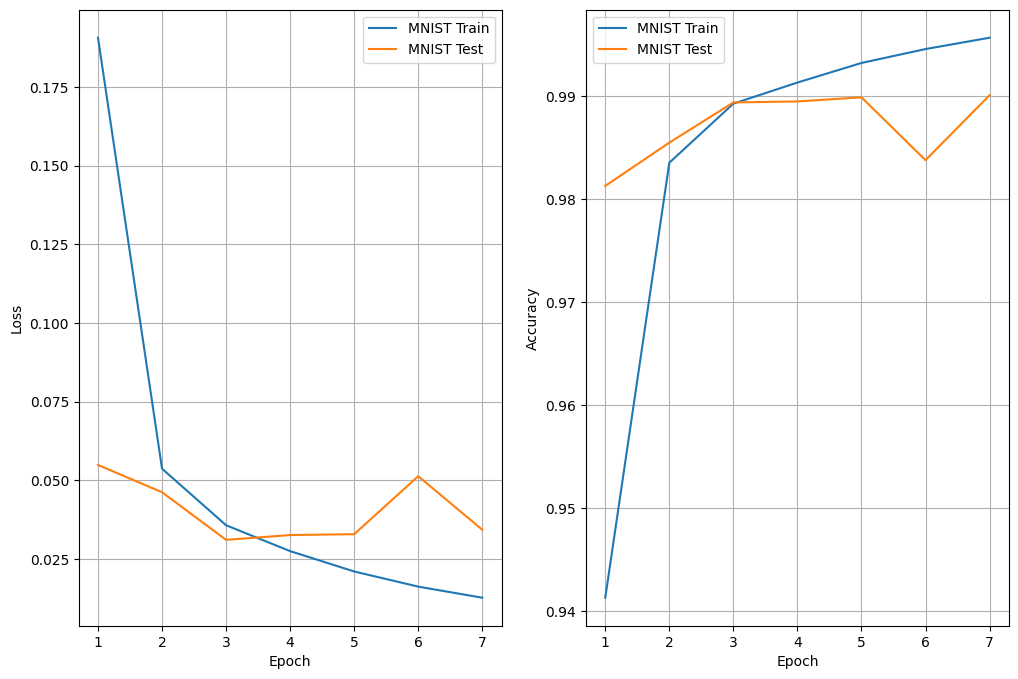

In [26]:
draw_history([history[0], history[2]], ["MNIST Train", "MNIST Test"], [history[1], history[3]], ["MNIST Train", "MNIST Test"])

In [27]:
class TwoHeadCNN(nn.Module):
    def __init__(self, cnn):
        super().__init__()
        self.layers = cnn.layers
        self.mnist_head = cnn.fc
        self.fashion_mnist_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=32*7*7, out_features=128),
            nn.LeakyReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x, mode="mnist"):
        x = self.layers(x)
        if mode == "mnist":
            x = self.mnist_head(x)
        elif mode == "fashion":
            x = self.fashion_mnist_head(x)
        else:
            raise ValueError(f"Unknown mode: {mode}")
        return x

In [28]:
two_headed_dragon = TwoHeadCNN(model).to(device)
torch.save(two_headed_dragon.state_dict(), "dragon.pth")
for param in two_headed_dragon.layers.parameters():
    param.requires_grad = False
optimizer = optim.Adam(filter(lambda x: x.requires_grad, two_headed_dragon.parameters()), lr=1e-3)
fashion_history = train(two_headed_dragon, fashion_train_loader, fashion_test_loader, nn.CrossEntropyLoss(), optimizer, 7, mode="fashion")

Epoch 1/7 | Train loss:0.396036 | Train accuracy:0.860733 | Test loss:0.360555 | Test accuracy:0.868300
Epoch 2/7 | Train loss:0.281758 | Train accuracy:0.897933 | Test loss:0.330223 | Test accuracy:0.880000
Epoch 3/7 | Train loss:0.247800 | Train accuracy:0.909967 | Test loss:0.293345 | Test accuracy:0.895200
Epoch 4/7 | Train loss:0.221931 | Train accuracy:0.917700 | Test loss:0.275836 | Test accuracy:0.902300
Epoch 5/7 | Train loss:0.201153 | Train accuracy:0.925083 | Test loss:0.295227 | Test accuracy:0.898400
Epoch 6/7 | Train loss:0.184587 | Train accuracy:0.931150 | Test loss:0.289890 | Test accuracy:0.901500
Epoch 7/7 | Train loss:0.170089 | Train accuracy:0.937783 | Test loss:0.297462 | Test accuracy:0.898500


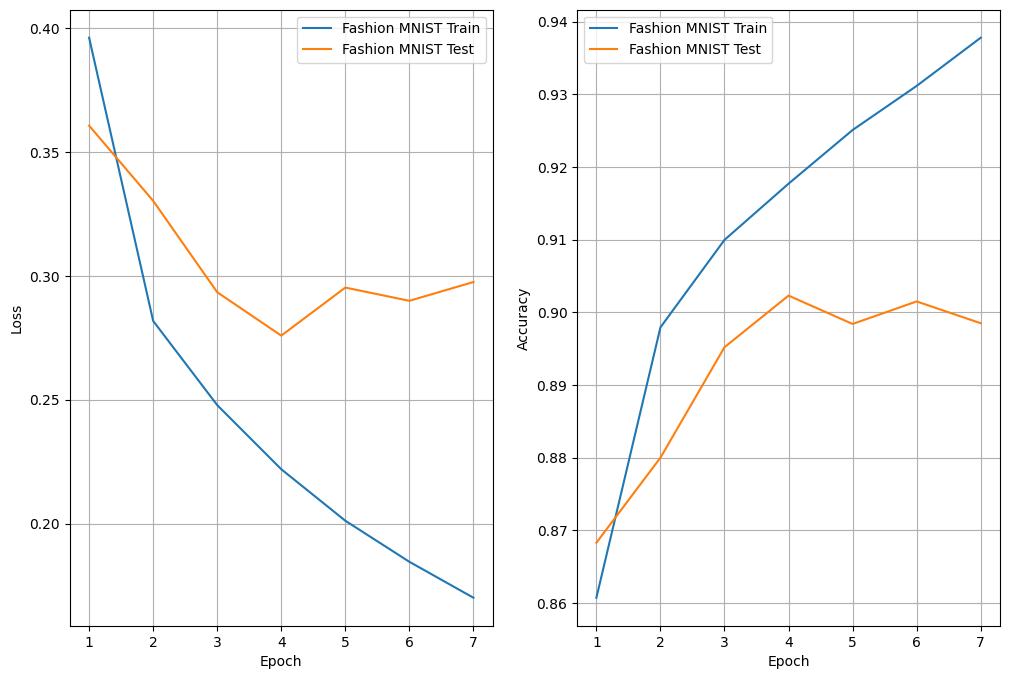

In [29]:
draw_history([fashion_history[0], fashion_history[2]], ["Fashion MNIST Train", "Fashion MNIST Test"], [fashion_history[1], fashion_history[3]], ["Fashion MNIST Train", "Fashion MNIST Test"])

In [30]:
def train_two(model, train_loader, test_loader, mnist_test_loader, risk, optimizer, epochs=7, mode=None):
    train_losses, test_losses, train_acc, test_acc, test2_losses, test2_acc = [], [], [], [], [], []
    for epoch in range(epochs):
        trl, tra, tel, tea = train(model, train_loader, test_loader, risk, optimizer, 1, mode=mode)
        train_losses.extend(trl)
        train_acc.extend(tra)
        test_losses.extend(tel)
        test_acc.extend(tea)
        te2l, te2a = evaluate(model, mnist_test_loader, risk, mode="mnist")
        test2_losses.append(te2l)
        test2_acc.append(te2a)
    return train_losses, test_losses, test2_losses, train_acc, test_acc, test2_acc

In [ ]:
for param in two_headed_dragon.layers.parameters():
    param.requires_grad = True
optimizer = optim.Adam(filter(lambda x: x.requires_grad, two_headed_dragon.parameters()), lr=1e-3)
unfrozen_history = train_two(two_headed_dragon, fashion_train_loader, fashion_test_loader, test_loader, nn.CrossEntropyLoss(), optimizer, 7, "fashion")

Epoch 1/1 | Train loss:0.164390 | Train accuracy:0.937417 | Test loss:0.290223 | Test accuracy:0.902700


In [ ]:
draw_history(unfrozen_history[:3], ["Fashion MNIST Train", "Fashion MNIST Test", "MNIST Test"], unfrozen_history[3:], ["Fashion MNIST Train", "Fashion MNIST Test", "MNIST Test"])

In [14]:
new_dragon = TwoHeadCNN(CNN()).to(device)
new_dragon.load_state_dict(torch.load("dragon.pth", map_location=device))
for param in new_dragon.layers.parameters():
    param.require_grad = True
optimizer = optim.Adam(filter(lambda x: x.requires_grad, new_dragon.parameters()), lr=1e-3)
new_unfrozen_history = train_two(new_dragon, fashion_train_loader, fashion_test_loader, test_loader, nn.CrossEntropyLoss(), optimizer, 7, "fashion")

Epoch 1/1 | Train loss:0.373228 | Train accuracy:0.868233 | Test loss:0.292090 | Test accuracy:0.894000
Epoch 1/1 | Train loss:0.257392 | Train accuracy:0.905867 | Test loss:0.290078 | Test accuracy:0.894400
Epoch 1/1 | Train loss:0.215968 | Train accuracy:0.920283 | Test loss:0.263712 | Test accuracy:0.901600
Epoch 1/1 | Train loss:0.188430 | Train accuracy:0.930017 | Test loss:0.239758 | Test accuracy:0.912800
Epoch 1/1 | Train loss:0.165845 | Train accuracy:0.939217 | Test loss:0.242779 | Test accuracy:0.913600
Epoch 1/1 | Train loss:0.144372 | Train accuracy:0.946583 | Test loss:0.228894 | Test accuracy:0.919700
Epoch 1/1 | Train loss:0.127567 | Train accuracy:0.952583 | Test loss:0.243840 | Test accuracy:0.916700


In [ ]:
draw_history(new_unfrozen_history[:3], ["Fashion MNIST Train", "Fashion MNIST Test", "MNIST Test"], new_unfrozen_history[3:], ["Fashion MNIST Train", "Fashion MNIST Test", "MNIST Test"])

In [ ]:
random_dragon = TwoHeadCNN(CNN()).to(device)
for param in random_dragon.parameters():
    nn.init.normal_(param)
for param in random_dragon.layers[0].parameters():
    param.requires_grad = False
optimizer = optim.Adam(filter(lambda x: x.requires_grad, random_dragon.parameters()), lr=1e-3)
random_history = train(random_dragon, fashion_train_loader, fashion_test_loader, nn.CrossEntropyLoss(), optimizer, 7, mode="fashion")

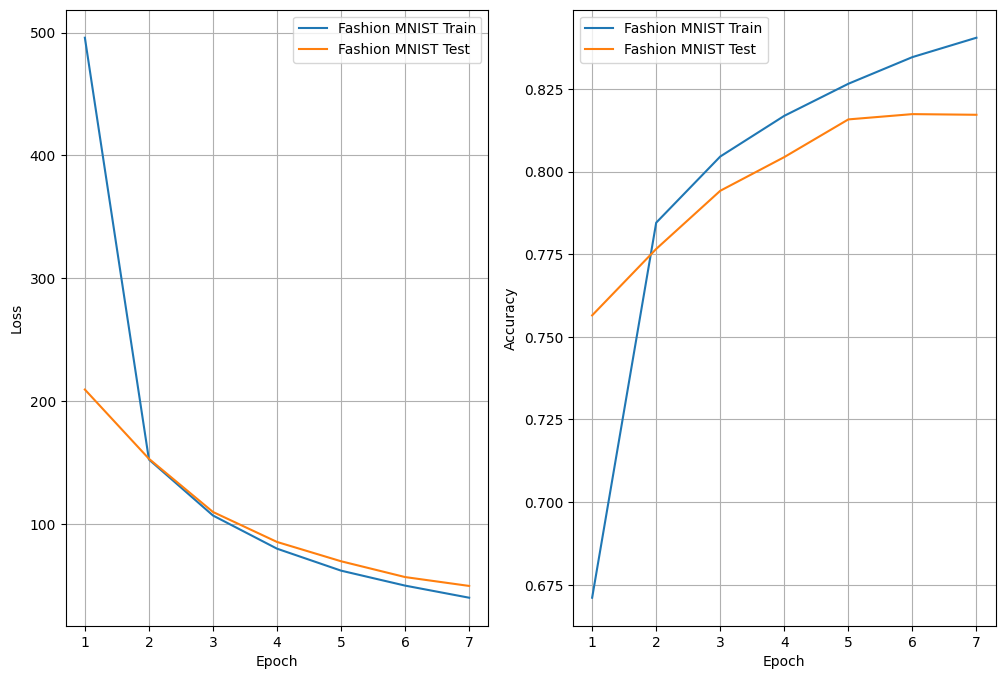

In [17]:
draw_history([random_history[0], random_history[2]], ["Fashion MNIST Train", "Fashion MNIST Test"], [random_history[1], random_history[3]], ["Fashion MNIST Train", "Fashion MNIST Test"])

In [ ]:
losses = [fashion_history[0], fashion_history[2]] + list(unfrozen_history[:2]) + list(new_unfrozen_history[:2]) + [random_history[0], random_history[2]]
labels = ["Frozen train", "Frozen test", "Fine-tuned train", "Fine-tuned test", "Loaded unfrozen train", "Loaded unfrozen test", "Random train", "Random test"]
accs = [fashion_history[1], fashion_history[3]] + list(unfrozen_history[3:5]) + list(new_unfrozen_history[3:5]) + [random_history[1], random_history[3]]
draw_history(losses, labels, accs, labels)

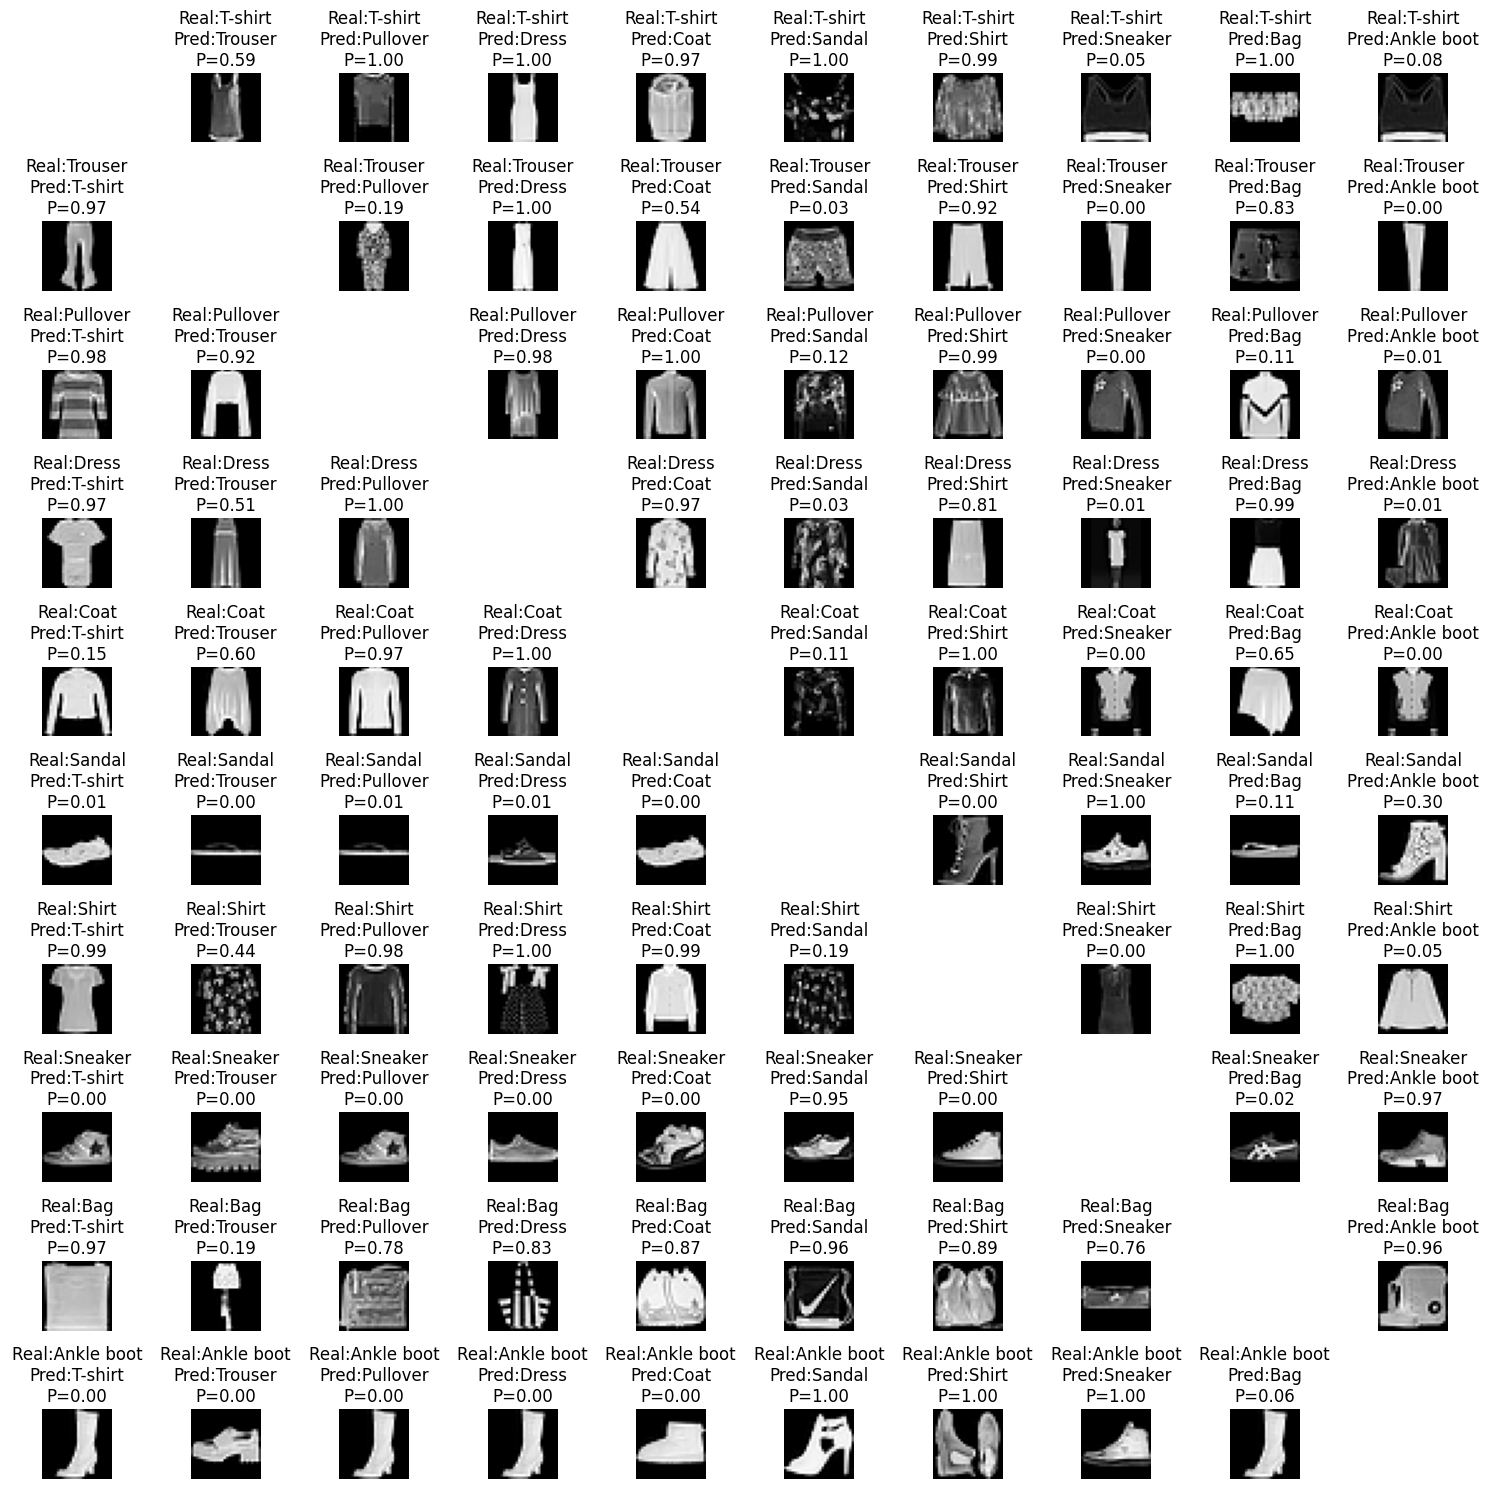

In [19]:
import torch.nn.functional as F
best_model = new_dragon
best_model.eval()
images, labels, probs = [], [], []
with torch.no_grad():
    for imgs, ls in fashion_test_loader:
        imgs = imgs.to(device)
        images.append(imgs.cpu())
        labels.append(ls)
        probs.append(F.softmax(best_model(imgs, mode="fashion"), dim=1))
images = torch.cat(images)
labels = torch.cat(labels)
probs = torch.cat(probs)
names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
fig, axes = plt.subplots(10, 10, figsize=(15, 15))
for c in range(10):
    for t in range(10):
        if c == t:
            axes[c, t].axis("off")
            continue
        idxs = torch.where(labels == c)[0]
        targets = probs[idxs, t]
        argmx = torch.argmax(targets)
        img_idx = idxs[argmx]
        axes[c, t].imshow(images[img_idx].squeeze(), cmap="gray")
        axes[c, t].set_title(f"Real:{names[c]}\nPred:{names[t]}\nP={probs[img_idx, t]:.2f}")
        axes[c, t].axis("off")

plt.tight_layout()
plt.show()